# 2단계 개선 실험 — 패딩 패치를 attention에서 제외 (pad-aware PatchTST)

**배경**
기준선은 8~31행짜리 짧은 세그먼트를 마지막 값 반복으로 32행까지 채워(패딩) 추론한다. 윈도우의 최대 75%가 가짜 평평한 구간이 되고, Transformer는 그 구간까지 참고해 실제 행을 재구성한다. 1단계에서 "미탐의 주원인은 패딩이 아니라 짧은 세그먼트의 정보량 부족"임이 드러났으므로 **기대치는 낮다.** 그래도 패딩이 끼치는 왜곡을 제거하면 분리도가 얼마나 달라지는지 확인한다.

**바꾸는 것 (pad-aware 모델)**
1. **RevIN 통계**: 윈도우 정규화의 mean/std를 실제 행에서만 계산 (패딩 값이 통계를 끌어당기지 않게)
2. **attention 제외**: 전부 패딩인 패치는 `src_key_padding_mask`로 다른 패치가 참조하지 못하게 하고, 출력 임베딩도 0으로 지워 head에 전달
3. **마스킹 대상**: 가릴 패치를 실제 패치 중에서만 고름 (패딩 패치를 가려 봐야 학습 신호가 없음)
4. **오차 계산**: 실제 행에서만 (기존과 동일)

**비교 변형**
| 변형 | 학습 | 추론 | 뜻 |
|---|---|---|---|
| A. 기준선 | 32행 이상 세그먼트만 | 패딩 윈도우를 그대로 입력 | 기존 노트북과 동일 |
| B. 추론만 pad-aware | A와 같은 모델 | 패딩 패치 attention 제외 | 모델은 그대로, 추론 왜곡만 제거 |
| C. 학습+추론 pad-aware | 8행 이상 세그먼트까지 학습에 포함(패딩 제외 학습) | 패딩 패치 attention 제외 | 모델이 짧은 세그먼트도 보고 배움 |

**판단 기준**: PR-AUC가 기준선 대비 −0.01 이내이면서 미탐이 10행 이상 줄면 채택. 아니면 기준선 유지하고 "효과 없음"으로 기록.

## 0. CONFIG · seed (기준선과 동일, 출력 폴더만 분리)

In [1]:
import os, random, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, f1_score, precision_score, recall_score
from sklearn.ensemble import IsolationForest

%matplotlib inline
warnings.filterwarnings("ignore")

CONFIG = {
    # ── 경로 ──
    "NORMAL_PATH": "press_data_normal.csv",
    "OUTLIER_PATH": "outlier_data.csv",
    "OUT_DIR": "patchtst_outputs_stage2",   # 2단계 실험 전용 출력 폴더 (기준선 결과 보존)
    # ── 컬럼 ──
    "TIME_COL": "TimeStamp",
    "LABEL_COL": "Equipment_state",
    "CHANNELS": ["AI0_Vibration", "AI1_Vibration", "AI2_Current"],   # 원본 센서 3개
    # ── 전처리 ──
    "NOMINAL_DT": 0.1,       # 명목 샘플링 주기(초). EDA에서 중앙값 0.1s 확인
    "GAP_FACTOR": 10,        # 중앙값의 10배(=1초) 넘는 간격이면 세그먼트를 끊는다
    "MAX_INTERP": 3,         # 이 샘플 수 이하의 짧은 결측만 선형 보간
    "TRAIN_RATIO": 0.8,      # normal 앞 80%를 train, 뒤 20%를 val (시간순)
    # ── 윈도우 ──
    # EDA: 세그먼트(버스트) 최대 길이가 50행(5초)이므로 윈도우는 50 이하여야 한다
    "WINDOW": 32,            # 윈도우 길이(샘플) = 3.2초
    "STRIDE": 4,             # 슬라이딩 간격
    "MIN_SEG_INFER": 8,      # 추론 시 이보다 짧은 세그먼트는 score를 매기지 않는다(패딩 한계)
    # ── 파생 변수 ──
    "use_features": True,    # True: 원본+파생 / False: 원본만  (6절에서 둘 다 비교한다)
    "ROLL_WIN": 10,          # 이동 통계 윈도우(샘플) = 1초
    # ── PatchTST ──
    "PATCH_LEN": 4,          # 패치 길이. (WINDOW-PATCH_LEN) % PATCH_STRIDE == 0 이어야 한다
    "PATCH_STRIDE": 4,       # = PATCH_LEN → 겹치지 않는 패치 (마스킹 시 정보 누출 방지)
    "D_MODEL": 64,           # 데이터 2만 행 → 소형 모델
    "N_HEADS": 4,
    "N_LAYERS": 2,
    "D_FF": 128,
    "DROPOUT": 0.1,
    "MASK_RATIO": 0.4,       # 학습 시 가리는 패치 비율 (PatchTST self-supervised 방식)
    "N_INFER_MASKS": 8,      # 추론 시 서로 다른 마스크 개수 (평균 내어 score 안정화)
    # ── 학습 ──
    "BATCH_SIZE": 64,
    "EPOCHS": 60,
    "LR": 1e-3,
    "PATIENCE": 8,           # val loss가 이 epoch 동안 안 좋아지면 중단
    "SEED": 42,
}
assert (CONFIG["WINDOW"] - CONFIG["PATCH_LEN"]) % CONFIG["PATCH_STRIDE"] == 0, "패치가 윈도우를 정확히 덮어야 한다"
os.makedirs(CONFIG["OUT_DIR"], exist_ok=True)


def set_seed(seed: int) -> None:
    """random / numpy / torch / cuda seed를 모두 고정한다. cudnn도 결정론 모드로 둔다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True   # 같은 입력 → 같은 출력 (속도는 약간 손해)
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["SEED"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)

# 그림 색: 정상=파랑, 이상=주황 (고정 순서, 색약 대비 검증된 조합). 임계값/경고=빨강
COLOR = {"normal": "#2a78d6", "outlier": "#eb6834", "thr": "#e34948", "gray": "#9a9a9a", "recon": "#2f9e6f"}
plt.rcParams.update({"axes.unicode_minus": False, "figure.dpi": 100})

torch 2.13.0+cu126 | device: cuda


## 1. 데이터 로드 · 전처리 (기준선과 동일)

In [2]:
def load_raw(path: str, cfg: dict) -> pd.DataFrame:
    """csv를 읽고 인덱스 컬럼 제거, 시간 컬럼을 datetime으로 변환한다."""
    df = pd.read_csv(path)
    unnamed = [c for c in df.columns if str(c).startswith("Unnamed")]   # 저장 시 섞인 인덱스 컬럼
    df = df.drop(columns=unnamed)
    df[cfg["TIME_COL"]] = pd.to_datetime(df[cfg["TIME_COL"]])
    return df


raw_normal = load_raw(CONFIG["NORMAL_PATH"], CONFIG)
raw_outlier = load_raw(CONFIG["OUTLIER_PATH"], CONFIG)

for name, df in [("normal", raw_normal), ("outlier", raw_outlier)]:
    tc = CONFIG["TIME_COL"]
    print(f"[{name}] shape={df.shape} | 기간 {df[tc].min()} ~ {df[tc].max()} "
          f"| 라벨 분포 {df[CONFIG['LABEL_COL']].value_counts().to_dict()}")

# 파일 자체가 라벨이다: normal 파일 = 전부 0, outlier 파일 = 전부 1 → 행 단위 라벨은 파일 단위 라벨과 같다
print(f"\n불균형 비율: {len(raw_normal)} : {len(raw_outlier)} = {len(raw_normal)/len(raw_outlier):.1f} : 1")

[normal] shape=(20000, 5) | 기간 2022-07-12 00:00:00.019000 ~ 2022-07-12 01:16:55.828000 | 라벨 분포 {0: 20000}
[outlier] shape=(600, 5) | 기간 2022-07-17 10:51:07.943000 ~ 2022-07-17 10:53:53.540000 | 라벨 분포 {1: 600}

불균형 비율: 20000 : 600 = 33.3 : 1


In [3]:
def resolve_duplicate_timestamps(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """동일 타임스탬프 행을 판별(완전 중복 / 값 충돌)하고 제거 또는 평균 병합한다."""
    tc, chs = cfg["TIME_COL"], cfg["CHANNELS"]
    n_ts_dup = int(df[tc].duplicated().sum())                 # 시각이 같은 '추가' 행 수
    n_full_dup = int(df.duplicated(subset=[tc] + chs).sum())  # 시각+값이 모두 같은 추가 행 수
    n_conflict = n_ts_dup - n_full_dup                        # 시각만 같고 값이 다른 행 수
    print(f"  동일 시각 행: {n_ts_dup}건 → 완전 중복 {n_full_dup}건 (제거), 값 충돌 {n_conflict}건 (평균 병합)")

    before = len(df)
    df = df.drop_duplicates(subset=[tc] + chs)                          # 완전 중복 제거
    df = df.groupby(tc, as_index=False)[chs].mean()                     # 남은 동일 시각은 평균 병합
    print(f"  행 수: {before} → {len(df)}")
    return df


print("[normal]");  normal_p = resolve_duplicate_timestamps(raw_normal, CONFIG)
print("[outlier]"); outlier_p = resolve_duplicate_timestamps(raw_outlier, CONFIG)

[normal]
  동일 시각 행: 1건 → 완전 중복 1건 (제거), 값 충돌 0건 (평균 병합)
  행 수: 20000 → 19999
[outlier]
  동일 시각 행: 0건 → 완전 중복 0건 (제거), 값 충돌 0건 (평균 병합)
  행 수: 600 → 600


In [4]:
def sort_by_time(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """시간순 정렬 + reset_index. 정렬 전후로 순서가 바뀐 행 수를 출력한다."""
    tc = cfg["TIME_COL"]
    n_unsorted = int((df[tc].diff().dt.total_seconds() < 0).sum())   # 시간이 거꾸로 가는 지점 수
    df = df.sort_values(tc).reset_index(drop=True)
    print(f"  시간 역행 지점 {n_unsorted}건 → 정렬 완료, 행 {len(df)}")
    return df


print("[normal]");  normal_p = sort_by_time(normal_p, CONFIG)
print("[outlier]"); outlier_p = sort_by_time(outlier_p, CONFIG)

[normal]
  시간 역행 지점 0건 → 정렬 완료, 행 19999
[outlier]
  시간 역행 지점 0건 → 정렬 완료, 행 600


In [5]:
def assign_segments(df: pd.DataFrame, cfg: dict, gap_sec: float, verbose: bool = True) -> pd.DataFrame:
    """앞 행과의 간격이 gap_sec를 넘는 지점마다 seg_id를 1씩 올려 세그먼트를 나눈다."""
    tc = cfg["TIME_COL"]
    dt = df[tc].diff().dt.total_seconds().fillna(0.0)
    df = df.copy()
    df["seg_id"] = (dt > gap_sec).cumsum().astype(int)
    if verbose:
        seg_len = df.groupby("seg_id").size()
        gaps = dt[dt > gap_sec]
        print(f"  갭 기준 {gap_sec:.2f}s | 세그먼트 {len(seg_len)}개 | 길이 min/median/max = "
              f"{seg_len.min()}/{int(seg_len.median())}/{seg_len.max()}행 | "
              f"갭 크기 min/median/max = {gaps.min():.2f}/{gaps.median():.2f}/{gaps.max():.2f}s")
    return df


GAP_SEC = CONFIG["NOMINAL_DT"] * CONFIG["GAP_FACTOR"]
print("[normal]");  normal_p = assign_segments(normal_p, CONFIG, GAP_SEC)
print("[outlier]"); outlier_p = assign_segments(outlier_p, CONFIG, GAP_SEC)

[normal]
  갭 기준 1.00s | 세그먼트 599개 | 길이 min/median/max = 1/37/50행 | 갭 크기 min/median/max = 1.54/4.22/16.64s
[outlier]
  갭 기준 1.00s | 세그먼트 21개 | 길이 min/median/max = 3/28/50행 | 갭 크기 min/median/max = 1.78/5.35/8.57s


In [6]:
def resample_segments(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """세그먼트별로 0.1초 격자에 맞추고, 짧은 결측만 선형 보간한다. 긴 결측은 삭제한다."""
    tc, chs, dt, max_interp = cfg["TIME_COL"], cfg["CHANNELS"], cfg["NOMINAL_DT"], cfg["MAX_INTERP"]
    out, n_interp, n_dropped, n_snap = [], 0, 0, 0
    for sid, seg in df.groupby("seg_id"):
        t0 = seg[tc].iloc[0]
        k = np.round((seg[tc] - t0).dt.total_seconds() / dt).astype(int)   # 격자 위치(정수)
        seg = seg.assign(k=k.values)
        g = seg.groupby("k")[chs].mean()                # 같은 격자로 스냅된 행은 평균
        g[tc] = seg.groupby("k")[tc].first()            # 실제 행은 원래 시각을 유지(제출 시 병합 키)
        n_snap += len(seg) - len(g)
        g = g.reindex(pd.RangeIndex(0, int(g.index.max()) + 1))   # 빠진 격자를 NaN 행으로 채움
        is_real = g[chs[0]].notna()
        # 결측 run 길이를 계산해 짧은 run만 보간 대상으로 표시
        isna = ~is_real
        run_id = (isna != isna.shift()).cumsum()
        run_len = isna.groupby(run_id).transform("size")
        fill_ok = isna & (run_len <= max_interp)
        interp = g[chs].interpolate("linear", limit_area="inside")
        g.loc[fill_ok, chs] = interp.loc[fill_ok, chs]
        n_interp += int(fill_ok.sum())
        still_na = g[chs[0]].isna()
        n_dropped += int(still_na.sum())
        g = g[~still_na].copy()
        # 보간된 행의 시각은 격자 시각으로 채운다
        grid_time = t0 + pd.to_timedelta(np.round(g.index.values * dt, 3), unit="s")
        g[tc] = g[tc].fillna(pd.Series(grid_time, index=g.index))
        g["is_interp"] = ~is_real[g.index]
        out.append(g[[tc] + chs + ["is_interp"]])
    res = pd.concat(out, ignore_index=True)
    print(f"  행 {len(df)} → {len(res)} | 같은 격자로 병합 {n_snap}행 | 보간 {n_interp}행 | 긴 결측으로 삭제 {n_dropped}격자")
    # 보간되지 않은 긴 결측이 남긴 틈에서 세그먼트를 다시 끊는다(2차 분리)
    res = assign_segments(res, cfg, gap_sec=dt * 1.5, verbose=True)
    return res


print("[normal]");  normal_p = resample_segments(normal_p, CONFIG)
print("[outlier]"); outlier_p = resample_segments(outlier_p, CONFIG)

# 파일 = 라벨 (normal 0, outlier 1)
normal_p["y"] = 0
outlier_p["y"] = 1

# 리샘플 결과 확인: 세그먼트 안의 간격은 전부 0.1초여야 한다
for name, df in [("normal", normal_p), ("outlier", outlier_p)]:
    d = df.groupby("seg_id")[CONFIG["TIME_COL"]].diff().dt.total_seconds().dropna()
    print(f"  {name}: 세그먼트 내부 간격 종류 = {sorted(d.round(3).unique())}")

[normal]


  행 19999 → 19999 | 같은 격자로 병합 0행 | 보간 0행 | 긴 결측으로 삭제 0격자
  갭 기준 0.15s | 세그먼트 599개 | 길이 min/median/max = 1/37/50행 | 갭 크기 min/median/max = 1.54/4.22/16.64s
[outlier]
  행 600 → 600 | 같은 격자로 병합 0행 | 보간 0행 | 긴 결측으로 삭제 0격자
  갭 기준 0.15s | 세그먼트 21개 | 길이 min/median/max = 3/28/50행 | 갭 크기 min/median/max = 1.78/5.35/8.57s
  normal: 세그먼트 내부 간격 종류 = [0.1]
  outlier: 세그먼트 내부 간격 종류 = [0.1]


In [7]:
def time_split(df: pd.DataFrame, ratio: float) -> pd.DataFrame:
    """앞 ratio 비율은 train, 나머지는 val. 경계를 다음 세그먼트 시작으로 이동한다."""
    df = df.copy()
    target = int(len(df) * ratio)
    seg_starts = df.index[df["seg_id"] != df["seg_id"].shift()]      # 각 세그먼트의 첫 행 위치
    split_at = int(seg_starts[seg_starts >= target][0])
    df["split"] = np.where(df.index < split_at, "train", "val")
    tc = CONFIG["TIME_COL"]
    for s in ["train", "val"]:
        part = df[df["split"] == s]
        print(f"  {s}: {len(part)}행, {part['seg_id'].nunique()}세그먼트, {part[tc].min().time()} ~ {part[tc].max().time()}")
    return df


normal_p = time_split(normal_p, CONFIG["TRAIN_RATIO"])
outlier_p["split"] = "test"

  train: 16009행, 481세그먼트, 00:00:00.019000 ~ 01:01:01.732000
  val: 3990행, 118세그먼트, 01:01:04.524000 ~ 01:16:55.828000


In [8]:
FEATURE_COLS = []   # 파생 변수 이름 목록 (아래에서 채움)


def add_features(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """세그먼트 내부에서만 차분 / 이동 std / 전류 이동 RMS를 계산한다."""
    df = df.copy()
    g = df.groupby("seg_id")
    w = cfg["ROLL_WIN"]
    cols = []
    for ch in cfg["CHANNELS"]:
        df[f"{ch}_diff"] = g[ch].diff().fillna(0.0)                                          # 세그먼트 첫 행은 0
        df[f"{ch}_rstd"] = g[ch].transform(lambda s: s.rolling(w, min_periods=2).std()).fillna(0.0)
        cols += [f"{ch}_diff", f"{ch}_rstd"]
    df["AI2_Current_rms"] = g["AI2_Current"].transform(lambda s: np.sqrt((s ** 2).rolling(w, min_periods=1).mean()))
    cols.append("AI2_Current_rms")
    return df, cols


normal_p, FEATURE_COLS = add_features(normal_p, CONFIG)
outlier_p, _ = add_features(outlier_p, CONFIG)
print("파생 변수:", FEATURE_COLS)

# 세그먼트 경계를 무시하고 차분하면 어떤 일이 생기는지 확인
naive_diff = normal_p["AI2_Current"].diff().abs()                     # 경계 무시
seg_diff = normal_p["AI2_Current_diff"].abs()                          # 세그먼트 내부
boundary = normal_p["seg_id"] != normal_p["seg_id"].shift()
print(f"경계 무시 차분의 99.9% 분위: 내부 {seg_diff.quantile(0.999):.1f} vs 경계에서 {naive_diff[boundary].quantile(0.999):.1f}"
      f" → 경계 행 {int(boundary.sum())}개가 가짜 급변으로 잡힌다")

파생 변수: ['AI0_Vibration_diff', 'AI0_Vibration_rstd', 'AI1_Vibration_diff', 'AI1_Vibration_rstd', 'AI2_Current_diff', 'AI2_Current_rstd', 'AI2_Current_rms']
경계 무시 차분의 99.9% 분위: 내부 94.2 vs 경계에서 460.6 → 경계 행 599개가 가짜 급변으로 잡힌다


In [9]:
def fit_stats(df: pd.DataFrame, cols: list) -> tuple:
    """train 행에서만 mean/std를 계산한다. std가 0인 컬럼은 나눗셈 보호."""
    mu = df[cols].mean()
    sd = df[cols].std().clip(lower=1e-6)
    return mu, sd


def apply_norm(df: pd.DataFrame, cols: list, mu, sd) -> np.ndarray:
    """(x - mu) / sd → float32 배열 [N, C]"""
    return ((df[cols] - mu) / sd).to_numpy(dtype=np.float32)


ALL_COLS = CONFIG["CHANNELS"] + FEATURE_COLS
train_rows = normal_p[normal_p["split"] == "train"]
MU, SD = fit_stats(train_rows, ALL_COLS)
print("train 통계 (원본 채널만 표시):")
print(pd.DataFrame({"mean": MU, "std": SD}).loc[CONFIG["CHANNELS"]].round(4))

# 통계 누수 검증: outlier로 정규화한 값과 train으로 정규화한 값의 스케일 차이
mu_leak, sd_leak = fit_stats(outlier_p, CONFIG["CHANNELS"])
print("\n만약 outlier 통계로 정규화했다면 |z| 평균:",
      ((outlier_p[CONFIG["CHANNELS"]] - mu_leak) / sd_leak).abs().mean().round(2).to_dict())
print("train 통계로 정규화한 outlier |z| 평균   :",
      ((outlier_p[CONFIG["CHANNELS"]] - MU[CONFIG["CHANNELS"]]) / SD[CONFIG["CHANNELS"]]).abs().mean().round(2).to_dict())

train 통계 (원본 채널만 표시):
                 mean       std
AI0_Vibration -0.0001    0.0743
AI1_Vibration -0.0000    0.1277
AI2_Current    1.2750  127.7931

만약 outlier 통계로 정규화했다면 |z| 평균: {'AI0_Vibration': 0.62, 'AI1_Vibration': 0.78, 'AI2_Current': 0.77}
train 통계로 정규화한 outlier |z| 평균   : {'AI0_Vibration': 3.75, 'AI1_Vibration': 1.47, 'AI2_Current': 0.99}


## 2. 기준선 함수 정의 (기준선과 동일: 윈도우 생성 · PatchTST · 학습 · score · 평가)

In [10]:
def make_windows(df: pd.DataFrame, Z: np.ndarray, cfg: dict, pad_short: bool, verbose: bool = True):
    """세그먼트 안에서 슬라이딩 윈도우를 만든다.
    반환: X [n, W, C] (정규화 값), IDX [n, W] (df 행 위치, 패딩은 -1)"""
    W, S, min_len = cfg["WINDOW"], cfg["STRIDE"], cfg["MIN_SEG_INFER"]
    X, IDX = [], []
    n_drop_seg = n_drop_rows = n_pad_seg = 0
    for sid, pos in df.groupby("seg_id").indices.items():     # pos: 이 세그먼트 행들의 위치 배열
        L = len(pos)
        if L >= W:
            starts = list(range(0, L - W + 1, S))
            if starts[-1] != L - W:
                starts.append(L - W)                            # 끝 맞춤 윈도우
            for s in starts:
                X.append(Z[pos[s:s + W]]); IDX.append(pos[s:s + W])
        elif pad_short and L >= min_len:
            pad = W - L
            X.append(np.concatenate([Z[pos], np.repeat(Z[pos[-1:]], pad, axis=0)]))   # 마지막 값 반복
            IDX.append(np.concatenate([pos, -np.ones(pad, dtype=int)]))
            n_pad_seg += 1
        else:
            n_drop_seg += 1; n_drop_rows += L
    X = np.stack(X).astype(np.float32); IDX = np.stack(IDX)
    if verbose:
        print(f"  윈도우 {len(X)}개 (shape {X.shape}) | 패딩 세그먼트 {n_pad_seg}개 | "
              f"버린 세그먼트 {n_drop_seg}개 ({n_drop_rows}행)")
    return X, IDX


def build_dataset(cols: list):
    """정규화 → 윈도우 생성까지. 학습용(train만, 패딩 없음)과 추론용(전체, 패딩 허용)을 함께 만든다."""
    Z_n = apply_norm(normal_p, cols, MU[cols], SD[cols])
    Z_o = apply_norm(outlier_p, cols, MU[cols], SD[cols])
    print(" [학습용 normal]");  X_all, IDX_all = make_windows(normal_p, Z_n, CONFIG, pad_short=False)
    split_arr = normal_p["split"].to_numpy()
    is_train = np.all(split_arr[IDX_all] == "train", axis=1)      # 윈도우 전체가 train에 속해야 함
    is_val = np.all(split_arr[IDX_all] == "val", axis=1)
    print(f"   → train 윈도우 {is_train.sum()}개, val 윈도우 {is_val.sum()}개, 경계 걸침 {(~is_train & ~is_val).sum()}개")
    print(" [추론용 normal]");  Xn_inf, IDXn_inf = make_windows(normal_p, Z_n, CONFIG, pad_short=True)
    print(" [추론용 outlier]"); Xo_inf, IDXo_inf = make_windows(outlier_p, Z_o, CONFIG, pad_short=True)
    return {"cols": cols, "X_train": X_all[is_train], "X_val": X_all[is_val],
            "Xn_inf": Xn_inf, "IDXn_inf": IDXn_inf, "Xo_inf": Xo_inf, "IDXo_inf": IDXo_inf}

In [11]:
class RevIN(nn.Module):
    """Reversible Instance Normalization.
    윈도우마다 채널별 mean/std로 정규화하고, 출력에서 되돌린다.
    → 정상/이상이 다른 날짜·부하에서 수집되어 생기는 '절대 수준 차이'를 제거하고 파형(형태)만 보게 한다.
    입력 [B, L, C] → 출력 [B, L, C]"""
    def __init__(self, n_ch: int, eps: float = 1e-5):
        super().__init__()
        self.eps = eps
        self.gamma = nn.Parameter(torch.ones(n_ch))    # 채널별 학습 가능한 scale
        self.beta = nn.Parameter(torch.zeros(n_ch))    # 채널별 학습 가능한 shift

    def forward(self, x: torch.Tensor, mode: str) -> torch.Tensor:
        if mode == "norm":
            self.mean = x.mean(dim=1, keepdim=True).detach()                        # [B, 1, C]
            self.std = torch.sqrt(x.var(dim=1, keepdim=True, unbiased=False) + self.eps).detach()
            return (x - self.mean) / self.std * self.gamma + self.beta
        elif mode == "denorm":
            return (x - self.beta) / (self.gamma + self.eps) * self.std + self.mean
        raise ValueError(mode)


class Patching(nn.Module):
    """[B, L, C] → [B*C, N, P]  (N = 패치 수, P = 패치 길이). 채널을 배치 차원으로 합쳐 채널 독립 처리."""
    def __init__(self, patch_len: int, stride: int):
        super().__init__()
        self.P, self.S = patch_len, stride

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, L, C = x.shape
        x = x.permute(0, 2, 1)                              # [B, C, L]
        x = x.unfold(dimension=2, size=self.P, step=self.S) # [B, C, N, P]
        return x.reshape(B * C, x.shape[2], self.P)         # [B*C, N, P]


class PatchTSTReconstructor(nn.Module):
    """마스킹 재구성용 PatchTST.
    forward(x [B, L, C], patch_mask [B*C, N] or None) → 재구성 x_hat [B, L, C]"""
    def __init__(self, n_ch: int, cfg: dict):
        super().__init__()
        L, P, S, D = cfg["WINDOW"], cfg["PATCH_LEN"], cfg["PATCH_STRIDE"], cfg["D_MODEL"]
        self.n_ch, self.L, self.P, self.S = n_ch, L, P, S
        self.N = (L - P) // S + 1                            # 패치 수
        self.revin = RevIN(n_ch)
        self.patching = Patching(P, S)
        self.proj = nn.Linear(P, D)                          # 패치 → 임베딩  [B*C, N, P] → [B*C, N, D]
        self.pos = nn.Parameter(torch.randn(1, self.N, D) * 0.02)   # 학습 가능한 위치 임베딩
        self.mask_token = nn.Parameter(torch.zeros(1, 1, D))        # 가려진 패치 자리에 넣는 토큰
        layer = nn.TransformerEncoderLayer(d_model=D, nhead=cfg["N_HEADS"], dim_feedforward=cfg["D_FF"],
                                           dropout=cfg["DROPOUT"], batch_first=True, activation="gelu")
        self.encoder = nn.TransformerEncoder(layer, num_layers=cfg["N_LAYERS"])
        self.head = nn.Sequential(nn.Flatten(start_dim=1), nn.Dropout(cfg["DROPOUT"]),
                                  nn.Linear(self.N * D, L))   # [B*C, N*D] → [B*C, L]

    def forward(self, x: torch.Tensor, patch_mask: torch.Tensor = None) -> torch.Tensor:
        B, L, C = x.shape
        x = self.revin(x, "norm")                             # [B, L, C]
        p = self.patching(x)                                  # [B*C, N, P]
        z = self.proj(p) + self.pos                           # [B*C, N, D]
        if patch_mask is not None:                            # 가려진 패치의 임베딩을 mask_token으로 교체
            m = patch_mask.unsqueeze(-1).bool()               # [B*C, N, 1]
            z = torch.where(m, self.mask_token.expand_as(z), z)
        z = self.encoder(z)                                   # [B*C, N, D]
        out = self.head(z)                                    # [B*C, L]
        out = out.view(B, C, L).permute(0, 2, 1)              # [B, L, C]
        return self.revin(out, "denorm")

    def patch_to_pos_mask(self, patch_mask: torch.Tensor, B: int) -> torch.Tensor:
        """패치 마스크 [B*C, N] → 위치 마스크 [B, L, C] (가려진 패치가 덮는 시점은 1)"""
        BC, N = patch_mask.shape
        pos = torch.zeros(BC, self.L, device=patch_mask.device)
        for n in range(N):
            seg = pos[:, n * self.S: n * self.S + self.P]
            pos[:, n * self.S: n * self.S + self.P] = torch.maximum(seg, patch_mask[:, n:n + 1])
        return pos.view(B, self.n_ch, self.L).permute(0, 2, 1)


def random_patch_mask(BC: int, N: int, ratio: float, gen: torch.Generator, device) -> torch.Tensor:
    """시퀀스마다 round(ratio*N)개의 패치를 무작위로 가린다. 반환 [BC, N] float(1=가림)"""
    k = max(1, int(round(ratio * N)))
    order = torch.rand(BC, N, generator=gen).argsort(dim=1)
    mask = torch.zeros(BC, N)
    mask.scatter_(1, order[:, :k], 1.0)
    return mask.to(device)


# 모델 크기 확인
_tmp = PatchTSTReconstructor(n_ch=len(ALL_COLS), cfg=CONFIG)
n_params = sum(p.numel() for p in _tmp.parameters())
print(f"패치 수 N = {_tmp.N}, 파라미터 수 = {n_params:,}")
with torch.no_grad():   # shape 확인용 더미 forward
    xb = torch.randn(2, CONFIG["WINDOW"], len(ALL_COLS))
    mk = random_patch_mask(2 * len(ALL_COLS), _tmp.N, CONFIG["MASK_RATIO"], torch.Generator().manual_seed(0), "cpu")
    print("입력", tuple(xb.shape), "→ 출력", tuple(_tmp(xb, mk).shape), "| 위치 마스크", tuple(_tmp.patch_to_pos_mask(mk, 2).shape))
del _tmp

패치 수 N = 8, 파라미터 수 = 84,276
입력 (2, 32, 10) → 출력 (2, 32, 10) | 위치 마스크 (2, 32, 10)


In [12]:
def masked_mse(x_hat, x, pos_mask):
    """가려진 위치에서만 MSE. pos_mask [B, L, C] (1=가림)"""
    return (((x_hat - x) ** 2) * pos_mask).sum() / pos_mask.sum().clamp(min=1.0)


def run_epoch(model, X, cfg, optimizer=None, gen=None):
    """한 epoch. optimizer가 None이면 평가 모드(가중치 갱신 없음)."""
    train = optimizer is not None
    model.train(train)
    n_ch, bs = X.shape[2], cfg["BATCH_SIZE"]
    order = torch.randperm(len(X), generator=gen) if train else torch.arange(len(X))
    total, count = 0.0, 0
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[order[i:i + bs].numpy()]).to(DEVICE)
        mask = random_patch_mask(xb.shape[0] * n_ch, model.N, cfg["MASK_RATIO"], gen, DEVICE)
        pos_mask = model.patch_to_pos_mask(mask, xb.shape[0])
        with torch.set_grad_enabled(train):
            loss = masked_mse(model(xb, mask), xb, pos_mask)
        if train:
            optimizer.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # Transformer 학습 안정화
            optimizer.step()
        total += loss.item() * len(xb); count += len(xb)
    return total / count


def train_model(X_train, X_val, cfg, tag: str):
    """학습 + early stopping. 최적 가중치를 OUT_DIR/patchtst_{tag}.pt 에 저장하고 학습 곡선을 반환한다."""
    set_seed(cfg["SEED"])
    model = PatchTSTReconstructor(n_ch=X_train.shape[2], cfg=cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["LR"], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["EPOCHS"])
    gen_train = torch.Generator().manual_seed(cfg["SEED"])
    hist, best, bad, best_state = {"train": [], "val": []}, float("inf"), 0, None
    path = os.path.join(cfg["OUT_DIR"], f"patchtst_{tag}.pt")
    t0 = time.time()
    for ep in range(1, cfg["EPOCHS"] + 1):
        tr = run_epoch(model, X_train, cfg, opt, gen_train)
        va = run_epoch(model, X_val, cfg, None, torch.Generator().manual_seed(cfg["SEED"] + 1))  # val 마스크 고정
        sched.step()
        hist["train"].append(tr); hist["val"].append(va)
        if va < best - 1e-6:
            best, bad = va, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, path)
        else:
            bad += 1
        if ep % 5 == 0 or ep == 1:
            print(f"  [{tag}] epoch {ep:3d} | train {tr:.4f} | val {va:.4f} | best {best:.4f}")
        if bad >= cfg["PATIENCE"]:
            print(f"  [{tag}] early stopping at epoch {ep} (best val {best:.4f})")
            break
    model.load_state_dict(best_state)
    print(f"  [{tag}] 학습 시간 {time.time() - t0:.1f}s, 가중치 저장 → {path}")
    return model, hist

In [13]:
@torch.no_grad()
def reconstruction_errors(model, X: np.ndarray, cfg: dict) -> np.ndarray:
    """윈도우별·시점별·채널별 재구성 오차 [n, L, C]. 여러 마스크에서 '가려졌을 때'의 오차를 평균한다."""
    model.eval()
    n_ch, bs, K = X.shape[2], cfg["BATCH_SIZE"] * 4, cfg["N_INFER_MASKS"]
    gen = torch.Generator().manual_seed(cfg["SEED"] + 7)      # 추론 마스크도 고정 → 재현 가능
    out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(DEVICE)
        B = xb.shape[0]
        sum_masked = torch.zeros_like(xb); cnt = torch.zeros_like(xb); sum_all = torch.zeros_like(xb)
        for _ in range(K):
            mask = random_patch_mask(B * n_ch, model.N, cfg["MASK_RATIO"], gen, DEVICE)
            pm = model.patch_to_pos_mask(mask, B)
            e = (model(xb, mask) - xb) ** 2
            sum_masked += e * pm; cnt += pm; sum_all += e
        err = torch.where(cnt > 0, sum_masked / cnt.clamp(min=1), sum_all / K)   # 한 번도 안 가려진 시점은 전체 평균
        out.append(err.cpu().numpy())
    return np.concatenate(out)


def aggregate_rows(err: np.ndarray, IDX: np.ndarray, n_rows: int) -> np.ndarray:
    """윈도우 오차 [n, L, C] → 행별 오차 [n_rows, C]. 겹치는 윈도우는 평균, 패딩(-1)은 제외, 미커버 행은 NaN."""
    C = err.shape[2]
    sums = np.zeros((n_rows, C)); cnt = np.zeros(n_rows)
    valid = IDX >= 0
    np.add.at(sums, IDX[valid], err[valid])
    np.add.at(cnt, IDX[valid], 1)
    row_err = np.full((n_rows, C), np.nan)
    row_err[cnt > 0] = sums[cnt > 0] / cnt[cnt > 0, None]
    return row_err


def score_patchtst(tag: str) -> dict:
    """normal(train/val)과 outlier 전체 행에 대해 채널별 오차와 score를 계산한다."""
    d, model = DATA[tag], MODELS[tag]
    err_n = aggregate_rows(reconstruction_errors(model, d["Xn_inf"], CONFIG), d["IDXn_inf"], len(normal_p))
    err_o = aggregate_rows(reconstruction_errors(model, d["Xo_inf"], CONFIG), d["IDXo_inf"], len(outlier_p))
    s_n, s_o = np.nanmean(err_n, axis=1), np.nanmean(err_o, axis=1)
    val_mask = (normal_p["split"] == "val").to_numpy()
    fill = np.nanmedian(s_n[val_mask])                     # score를 못 매긴 행(너무 짧은 세그먼트)은 val 중앙값 = "정상으로 간주"
    print(f"  [{tag}] score 없는 행: normal {np.isnan(s_n).sum()}, outlier {np.isnan(s_o).sum()} → val 중앙값 {fill:.4f}으로 채움")
    return {"err_n": err_n, "err_o": err_o,
            "scored_n": ~np.isnan(s_n), "scored_o": ~np.isnan(s_o),
            "score_n": np.where(np.isnan(s_n), fill, s_n), "score_o": np.where(np.isnan(s_o), fill, s_o),
            "cols": d["cols"]}

In [14]:
VAL_MASK = (normal_p["split"] == "val").to_numpy()
TRAIN_MASK = ~VAL_MASK


def thresholds_from_val(score_val: np.ndarray) -> dict:
    """라벨 없이 val 정상 score 분포에서 임계값을 정한다."""
    return {"val_p99": float(np.percentile(score_val, 99)),
            "val_mean+3sd": float(score_val.mean() + 3 * score_val.std())}


def best_f1_threshold(y: np.ndarray, s: np.ndarray) -> float:
    """라벨을 써서 F1이 최대가 되는 임계값 (낙관적 상한)."""
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[int(np.argmax(f1))])


def evaluate(score_val: np.ndarray, score_out: np.ndarray, name: str) -> pd.DataFrame:
    """val 정상(0) + outlier(1)에 대해 AUROC / PR-AUC와 임계값별 F1을 계산한다."""
    y = np.r_[np.zeros(len(score_val)), np.ones(len(score_out))]
    s = np.r_[score_val, score_out]
    thr = thresholds_from_val(score_val); thr["best_f1"] = best_f1_threshold(y, s)
    rows = []
    for tname, t in thr.items():
        pred = (s >= t).astype(int)
        rows.append({"model": name, "threshold": tname, "thr_value": t,
                     "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
                     "F1": f1_score(y, pred), "AUROC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
                     "FP(val)": int(((pred == 1) & (y == 0)).sum()), "FN(out)": int(((pred == 0) & (y == 1)).sum())})
    return pd.DataFrame(rows), thr

## 3. pad-aware 모델 · 마스크 · 학습 · score 함수
기준선 클래스를 상속해 **패딩 정보(`pad_pos`)를 추가로 받는 forward**만 덧붙인다. `pad_pos`가 None이면 기준선과 완전히 같은 동작을 한다.

shape 표기: `pad_pos [B, L, C]` (True = 패딩 위치) → `pad_patch [B*C, N]` (True = 모든 위치가 패딩인 패치)

In [15]:
class RevINMasked(RevIN):
    """RevIN과 같지만 valid [B, L, C] (1=실제 행) 가중치로 mean/std를 실제 행에서만 계산한다."""
    def forward(self, x, mode, valid=None):
        if mode == "norm":
            if valid is None:
                return super().forward(x, "norm")
            cnt = valid.sum(dim=1, keepdim=True).clamp(min=1.0)                      # [B, 1, C] 실제 행 수
            self.mean = ((x * valid).sum(dim=1, keepdim=True) / cnt).detach()
            var = (((x - self.mean) ** 2) * valid).sum(dim=1, keepdim=True) / cnt
            self.std = torch.sqrt(var + self.eps).detach()
            return (x - self.mean) / self.std * self.gamma + self.beta
        return super().forward(x, "denorm")


class PatchTSTPadAware(PatchTSTReconstructor):
    """패딩 패치를 attention에서 제외하는 PatchTST. pad_pos=None이면 기준선과 동일."""
    def __init__(self, n_ch, cfg):
        super().__init__(n_ch, cfg)
        self.revin = RevINMasked(n_ch)                                   # 실제 행 기준 정규화로 교체
        layer = nn.TransformerEncoderLayer(d_model=cfg["D_MODEL"], nhead=cfg["N_HEADS"], dim_feedforward=cfg["D_FF"],
                                           dropout=cfg["DROPOUT"], batch_first=True, activation="gelu")
        # key_padding_mask를 쓸 때 nested tensor 경로를 끄는 편이 재현성과 호환성에 안전
        self.encoder = nn.TransformerEncoder(layer, num_layers=cfg["N_LAYERS"], enable_nested_tensor=False)

    def pad_patches(self, pad_pos: torch.Tensor) -> torch.Tensor:
        """pad_pos [B, L, C] → pad_patch [B*C, N] (패치의 모든 위치가 패딩이면 True)"""
        return self.patching(pad_pos.float()).min(dim=-1).values.bool()

    def forward(self, x, patch_mask=None, pad_pos=None):
        B, L, C = x.shape
        valid = None if pad_pos is None else (~pad_pos).float()
        x = self.revin(x, "norm", valid)                                 # [B, L, C]
        z = self.proj(self.patching(x)) + self.pos                       # [B*C, N, D]
        if patch_mask is not None:
            z = torch.where(patch_mask.unsqueeze(-1).bool(), self.mask_token.expand_as(z), z)
        key_pad = None
        if pad_pos is not None:
            key_pad = self.pad_patches(pad_pos)                          # [B*C, N]
        z = self.encoder(z, src_key_padding_mask=key_pad)                # 패딩 패치는 key로 참조되지 않음
        if key_pad is not None:
            z = z.masked_fill(key_pad.unsqueeze(-1), 0.0)                # 패딩 패치의 출력도 head에 넘기지 않음
        out = self.head(z).view(B, C, L).permute(0, 2, 1)
        return self.revin(out, "denorm")


def random_patch_mask_valid(pad_patch: torch.Tensor, ratio: float, gen: torch.Generator) -> torch.Tensor:
    """실제 패치 중에서만 round(ratio × 실제 패치 수)개를 가린다. pad_patch [BC, N] (True=패딩)"""
    BC, N = pad_patch.shape
    n_real = (~pad_patch).sum(dim=1)                                      # [BC]
    k = torch.clamp(torch.round(ratio * n_real.float()), min=1).long()
    r = torch.rand(BC, N, generator=gen)
    r[pad_patch.cpu()] = float("inf")                                    # 패딩 패치는 절대 선택되지 않게
    rank = r.argsort(dim=1).argsort(dim=1)                               # 각 패치의 순위
    return (rank < k.cpu().unsqueeze(1)).float().to(pad_patch.device)


def pad_pos_from_idx(IDX: np.ndarray, n_ch: int) -> np.ndarray:
    """IDX [n, W] (-1 = 패딩) → pad_pos [n, W, C] bool"""
    return np.repeat((IDX < 0)[:, :, None], n_ch, axis=2)


def run_epoch_pad(model, X, PAD, cfg, optimizer=None, gen=None):
    """run_epoch의 pad-aware 버전. 가릴 패치는 실제 패치 중에서, 손실은 실제 행의 가려진 위치에서만."""
    train = optimizer is not None
    model.train(train)
    bs = cfg["BATCH_SIZE"]
    order = torch.randperm(len(X), generator=gen) if train else torch.arange(len(X))
    total, count = 0.0, 0
    for i in range(0, len(X), bs):
        sel = order[i:i + bs].numpy()
        xb = torch.from_numpy(X[sel]).to(DEVICE); pb = torch.from_numpy(PAD[sel]).to(DEVICE)
        pad_patch = model.pad_patches(pb)
        mask = random_patch_mask_valid(pad_patch, cfg["MASK_RATIO"], gen)
        pos_mask = model.patch_to_pos_mask(mask, xb.shape[0]) * (~pb).float()      # 실제 행 ∩ 가려진 위치
        with torch.set_grad_enabled(train):
            loss = masked_mse(model(xb, mask, pb), xb, pos_mask)
        if train:
            optimizer.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); optimizer.step()
        total += loss.item() * len(xb); count += len(xb)
    return total / count


def train_model_pad(X_train, PAD_train, X_val, PAD_val, cfg, tag):
    """train_model의 pad-aware 버전 (early stopping, best 가중치 저장 동일)."""
    set_seed(cfg["SEED"])
    model = PatchTSTPadAware(n_ch=X_train.shape[2], cfg=cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["LR"], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["EPOCHS"])
    gen_train = torch.Generator().manual_seed(cfg["SEED"])
    hist, best, bad, best_state = {"train": [], "val": []}, float("inf"), 0, None
    path = os.path.join(cfg["OUT_DIR"], f"patchtst_{tag}.pt"); t0 = time.time()
    for ep in range(1, cfg["EPOCHS"] + 1):
        tr = run_epoch_pad(model, X_train, PAD_train, cfg, opt, gen_train)
        va = run_epoch_pad(model, X_val, PAD_val, cfg, None, torch.Generator().manual_seed(cfg["SEED"] + 1))
        sched.step(); hist["train"].append(tr); hist["val"].append(va)
        if va < best - 1e-6:
            best, bad = va, 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}; torch.save(best_state, path)
        else:
            bad += 1
        if ep % 10 == 0 or ep == 1: print(f"  [{tag}] epoch {ep:3d} | train {tr:.4f} | val {va:.4f} | best {best:.4f}")
        if bad >= cfg["PATIENCE"]: print(f"  [{tag}] early stopping at epoch {ep}"); break
    model.load_state_dict(best_state); print(f"  [{tag}] 학습 시간 {time.time() - t0:.1f}s → {path}")
    return model, hist


@torch.no_grad()
def reconstruction_errors_pad(model, X, PAD, cfg):
    """reconstruction_errors의 pad-aware 버전. 패딩 패치는 attention에서 제외, 가림은 실제 패치 중에서만."""
    model.eval()
    bs, K = cfg["BATCH_SIZE"] * 4, cfg["N_INFER_MASKS"]
    gen = torch.Generator().manual_seed(cfg["SEED"] + 7); out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(DEVICE); pb = torch.from_numpy(PAD[i:i + bs]).to(DEVICE)
        B = xb.shape[0]; pad_patch = model.pad_patches(pb)
        sum_masked = torch.zeros_like(xb); cnt = torch.zeros_like(xb); sum_all = torch.zeros_like(xb)
        for _ in range(K):
            mask = random_patch_mask_valid(pad_patch, cfg["MASK_RATIO"], gen)
            pm = model.patch_to_pos_mask(mask, B)
            e = (model(xb, mask, pb) - xb) ** 2
            sum_masked += e * pm; cnt += pm; sum_all += e
        out.append(torch.where(cnt > 0, sum_masked / cnt.clamp(min=1), sum_all / K).cpu().numpy())
    return np.concatenate(out)


# shape 확인
_m = PatchTSTPadAware(len(ALL_COLS), CONFIG)
_x = torch.randn(2, CONFIG["WINDOW"], len(ALL_COLS)); _pad = torch.zeros(2, CONFIG["WINDOW"], len(ALL_COLS), dtype=torch.bool); _pad[1, 12:, :] = True   # 두 번째 윈도우는 12행만 실제
_pp = _m.pad_patches(_pad); print("pad_patch (윈도우 2, 채널 0):", _pp.view(2, len(ALL_COLS), -1)[1, 0].int().tolist(), "→ 패치 3개 실제, 5개 패딩")
_mk = random_patch_mask_valid(_pp, CONFIG["MASK_RATIO"], torch.Generator().manual_seed(0)); print("가린 패치 (윈도우 2, 채널 0):", _mk.view(2, len(ALL_COLS), -1)[1, 0].int().tolist(), "→ 실제 패치 중에서만 선택")
with torch.no_grad(): print("출력 shape:", tuple(_m(_x, _mk, _pad).shape))
del _m

pad_patch (윈도우 2, 채널 0): [0, 0, 0, 1, 1, 1, 1, 1] → 패치 3개 실제, 5개 패딩
가린 패치 (윈도우 2, 채널 0): [1, 0, 0, 0, 0, 0, 0, 0] → 실제 패치 중에서만 선택


출력 shape: (2, 32, 10)


## 4. 세 변형 실행
- A: 기준선 모델(`train_model`) + 기준선 추론(`reconstruction_errors`) — 기존 노트북 수치가 재현되어야 한다
- B: A의 모델 가중치를 그대로 pad-aware 클래스에 옮겨 싣고, 추론만 pad-aware
- C: 8행 이상 세그먼트까지 학습에 포함해 pad-aware로 학습·추론

In [16]:
def evaluate_variant(name, score_n, score_o, unscored_o):
    """val/outlier score → 비교표 한 줄 + 세그먼트 길이 구간별 FN/FP"""
    fill = np.nanmedian(score_n[VAL_MASK])
    score_n = np.where(np.isnan(score_n), fill, score_n); score_o = np.where(np.isnan(score_o), fill, score_o)
    ev, thr = evaluate(score_n[VAL_MASK], score_o, name)
    row = ev[ev["threshold"] == "val_p99"].iloc[0]
    W = CONFIG["WINDOW"]
    L_o = outlier_p.groupby("seg_id")["seg_id"].transform("size").to_numpy()
    L_v = normal_p.groupby("seg_id")["seg_id"].transform("size").to_numpy()[VAL_MASK]
    bucket = lambda L: np.where(L < 8, "score 없음(<8)", np.where(L < 16, "패딩(8~15)", np.where(L < W, "패딩(16~31)", "정상 윈도우(≥32)")))
    pred_o = score_o >= thr["val_p99"]; pred_v = score_n[VAL_MASK] >= thr["val_p99"]
    fn_by = pd.Series(~pred_o).groupby(bucket(L_o)).sum().to_dict()
    fp_by = pd.Series(pred_v).groupby(bucket(L_v)).sum().to_dict()
    return {"name": name, "score_n": score_n, "score_o": score_o, "thr": thr, "eval": ev,
            "summary": {"variant": name, "AUROC": row["AUROC"], "PR-AUC": row["PR-AUC"], "F1@p99": row["F1"], "precision": row["precision"],
                        "recall": row["recall"], "thr_p99": thr["val_p99"], "FN": int(row["FN(out)"]), "FP": int(row["FP(val)"]),
                        "F1@bestF1": float(ev[ev["threshold"] == "best_f1"]["F1"].iloc[0]), "unscored_out": unscored_o},
            "fn_by": fn_by, "fp_by": fp_by}


V = {}
n_ch = len(ALL_COLS)
d = build_dataset(ALL_COLS)        # 기준선과 동일한 윈도우 (학습: 32행 이상만 / 추론: 패딩 포함)
PAD_n = pad_pos_from_idx(d["IDXn_inf"], n_ch); PAD_o = pad_pos_from_idx(d["IDXo_inf"], n_ch)

# ── A. 기준선 ──
print("=== A. 기준선 ===")
model_A, hist_A = train_model(d["X_train"], d["X_val"], CONFIG, "A_baseline")
err_n = aggregate_rows(reconstruction_errors(model_A, d["Xn_inf"], CONFIG), d["IDXn_inf"], len(normal_p))
err_o = aggregate_rows(reconstruction_errors(model_A, d["Xo_inf"], CONFIG), d["IDXo_inf"], len(outlier_p))
V["A"] = evaluate_variant("A. baseline", np.nanmean(err_n, 1), np.nanmean(err_o, 1), int(np.isnan(err_o[:, 0]).sum()))
V["A"]["err_o"] = err_o
print(f"  PR-AUC {V['A']['summary']['PR-AUC']:.4f} | F1@p99 {V['A']['summary']['F1@p99']:.4f} | FN {V['A']['summary']['FN']} | FN 구간별 {V['A']['fn_by']}")

# ── B. 같은 가중치, 추론만 pad-aware ──
print("\n=== B. 추론만 pad-aware (A의 가중치 재사용) ===")
model_B = PatchTSTPadAware(n_ch, CONFIG).to(DEVICE)
missing = model_B.load_state_dict(model_A.state_dict(), strict=True)     # 파라미터 이름·shape이 같아야 한다
err_n = aggregate_rows(reconstruction_errors_pad(model_B, d["Xn_inf"], PAD_n, CONFIG), d["IDXn_inf"], len(normal_p))
err_o = aggregate_rows(reconstruction_errors_pad(model_B, d["Xo_inf"], PAD_o, CONFIG), d["IDXo_inf"], len(outlier_p))
V["B"] = evaluate_variant("B. pad-aware inference", np.nanmean(err_n, 1), np.nanmean(err_o, 1), int(np.isnan(err_o[:, 0]).sum()))
V["B"]["err_o"] = err_o
print(f"  PR-AUC {V['B']['summary']['PR-AUC']:.4f} | F1@p99 {V['B']['summary']['F1@p99']:.4f} | FN {V['B']['summary']['FN']} | FN 구간별 {V['B']['fn_by']}")

# ── C. 짧은 세그먼트 포함 학습 + pad-aware 추론 ──
print("\n=== C. 학습+추론 pad-aware (8행 이상 세그먼트 학습 포함) ===")
split_arr = normal_p["split"].to_numpy()
real_split = np.where(d["IDXn_inf"] >= 0, split_arr[np.clip(d["IDXn_inf"], 0, None)], "pad")
is_train_c = np.all((real_split == "train") | (real_split == "pad"), axis=1)
is_val_c = np.all((real_split == "val") | (real_split == "pad"), axis=1)
X_tr_c, PAD_tr_c = d["Xn_inf"][is_train_c], PAD_n[is_train_c]
X_va_c, PAD_va_c = d["Xn_inf"][is_val_c], PAD_n[is_val_c]
print(f"  train 윈도우 {len(X_tr_c)}개 (기준선 {len(d['X_train'])}개, 패딩 윈도우 {int((PAD_tr_c[:, -1, 0]).sum())}개 추가) | val 윈도우 {len(X_va_c)}개")
model_C, hist_C = train_model_pad(X_tr_c, PAD_tr_c, X_va_c, PAD_va_c, CONFIG, "C_padaware")
err_n = aggregate_rows(reconstruction_errors_pad(model_C, d["Xn_inf"], PAD_n, CONFIG), d["IDXn_inf"], len(normal_p))
err_o = aggregate_rows(reconstruction_errors_pad(model_C, d["Xo_inf"], PAD_o, CONFIG), d["IDXo_inf"], len(outlier_p))
V["C"] = evaluate_variant("C. pad-aware train+infer", np.nanmean(err_n, 1), np.nanmean(err_o, 1), int(np.isnan(err_o[:, 0]).sum()))
V["C"]["err_o"] = err_o
print(f"  PR-AUC {V['C']['summary']['PR-AUC']:.4f} | F1@p99 {V['C']['summary']['F1@p99']:.4f} | FN {V['C']['summary']['FN']} | FN 구간별 {V['C']['fn_by']}")

 [학습용 normal]
  윈도우 1711개 (shape (1711, 32, 10)) | 패딩 세그먼트 0개 | 버린 세그먼트 249개 (3970행)
   → train 윈도우 1373개, val 윈도우 338개, 경계 걸침 0개
 [추론용 normal]
  윈도우 1911개 (shape (1911, 32, 10)) | 패딩 세그먼트 200개 | 버린 세그먼트 49개 (190행)
 [추론용 outlier]
  윈도우 53개 (shape (53, 32, 10)) | 패딩 세그먼트 9개 | 버린 세그먼트 3개 (11행)
=== A. 기준선 ===


  [A_baseline] epoch   1 | train 0.4409 | val 0.1171 | best 0.1171


  [A_baseline] epoch   5 | train 0.1890 | val 0.0823 | best 0.0823


  [A_baseline] epoch  10 | train 0.1445 | val 0.0668 | best 0.0668


  [A_baseline] epoch  15 | train 0.1306 | val 0.0616 | best 0.0616


...

  [C_padaware] epoch  30 | train 0.1155 | val 0.0559 | best 0.0559


  [C_padaware] epoch  40 | train 0.1110 | val 0.0540 | best 0.0540


  [C_padaware] epoch  50 | train 0.1089 | val 0.0534 | best 0.0533


  [C_padaware] epoch  60 | train 0.1095 | val 0.0532 | best 0.0532
  [C_padaware] 학습 시간 5.9s → patchtst_outputs_stage2/patchtst_C_padaware.pt


  PR-AUC 0.9559 | F1@p99 0.9189 | FN 56 | FN 구간별 {'score 없음(<8)': 11, '정상 윈도우(≥32)': 9, '패딩(16~31)': 16, '패딩(8~15)': 20}


## 5. 비교표와 그림

,AUROC,PR-AUC,F1@p99,precision,recall,thr_p99,FN,FP,F1@bestF1,unscored_out
variant,,,,,,,,,,
A. baseline,0.9776,0.9490,0.9088,0.9302,0.8883,0.5355,67,40,0.9135,11
B. pad-aware inference,0.9792,0.9537,0.9143,0.9309,0.8983,0.4808,61,40,0.9193,11
C. pad-aware train+infer,0.9798,0.9559,0.9189,0.9315,0.9067,0.4151,56,40,0.9231,11


미탐(FN) 세그먼트 길이 구간별


,A,B,C
score 없음(<8),11,11,11
패딩(8~15),23,19,20
패딩(16~31),18,19,16
정상 윈도우(≥32),15,12,9
합계,67,61,56


오탐(FP) 세그먼트 길이 구간별 (p99라 합계 ≈40 고정, 분포만 비교)


,A,B,C
score 없음(<8),0,0,0
패딩(8~15),13,12,7
패딩(16~31),9,6,6
정상 윈도우(≥32),18,22,27
합계,40,40,40


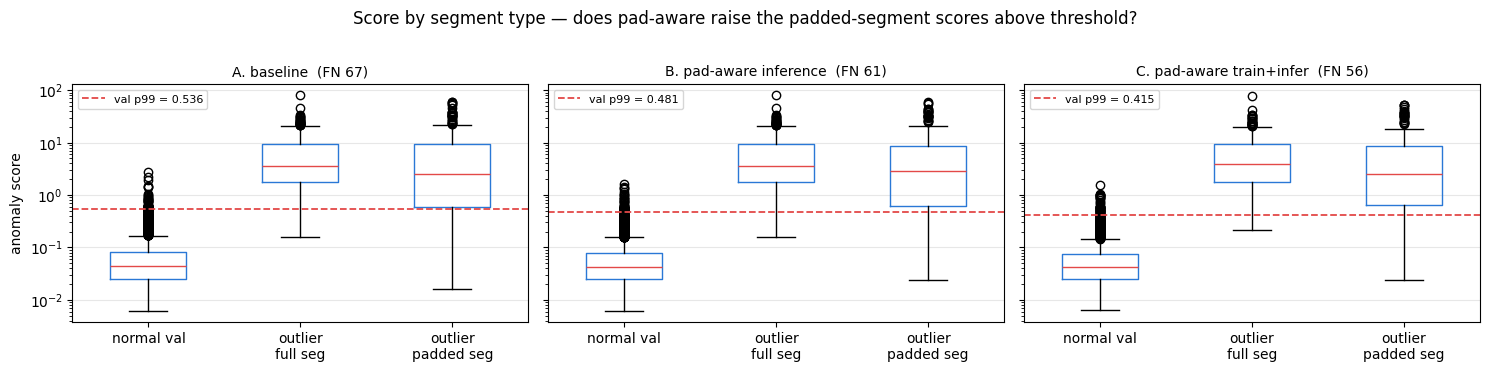

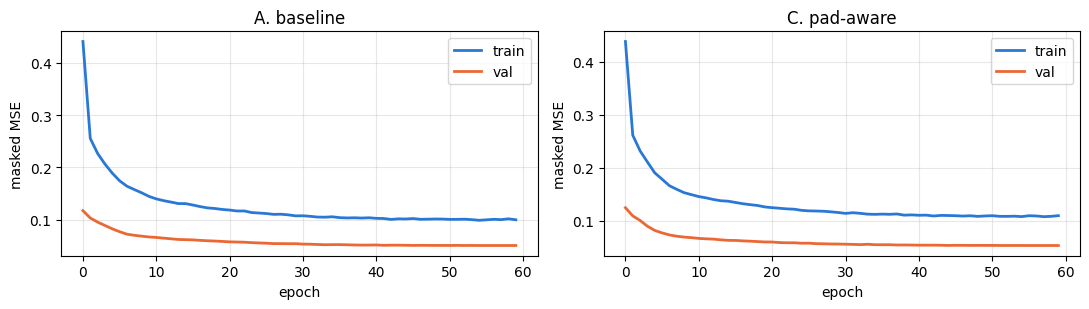

In [17]:
cmp = pd.DataFrame([v["summary"] for v in V.values()]).set_index("variant")
display(cmp.round(4))
fn_tbl = pd.DataFrame({k: v["fn_by"] for k, v in V.items()}).fillna(0).astype(int)
fn_tbl = fn_tbl.reindex(["score 없음(<8)", "패딩(8~15)", "패딩(16~31)", "정상 윈도우(≥32)"]); fn_tbl.loc["합계"] = fn_tbl.sum()
print("미탐(FN) 세그먼트 길이 구간별"); display(fn_tbl)
fp_tbl = pd.DataFrame({k: v["fp_by"] for k, v in V.items()}).fillna(0).astype(int)
fp_tbl = fp_tbl.reindex(["score 없음(<8)", "패딩(8~15)", "패딩(16~31)", "정상 윈도우(≥32)"]); fp_tbl.loc["합계"] = fp_tbl.sum()
print("오탐(FP) 세그먼트 길이 구간별 (p99라 합계 ≈40 고정, 분포만 비교)"); display(fp_tbl)
cmp.to_csv(os.path.join(CONFIG["OUT_DIR"], "stage2_padaware_comparison.csv"))

# 패딩 세그먼트에 속한 outlier 행의 score 분포가 변형별로 어떻게 달라지는지
L_o = outlier_p.groupby("seg_id")["seg_id"].transform("size").to_numpy()
pad_rows = (L_o >= 8) & (L_o < CONFIG["WINDOW"]); full_rows = L_o >= CONFIG["WINDOW"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, (k, v) in zip(axes, V.items()):
    s_o, s_v, t = v["score_o"], v["score_n"][VAL_MASK], v["thr"]["val_p99"]
    ax.boxplot([s_v, s_o[full_rows], s_o[pad_rows]], labels=["normal val", "outlier\nfull seg", "outlier\npadded seg"], widths=0.5,
               boxprops=dict(color=COLOR["normal"]), medianprops=dict(color=COLOR["thr"]))
    ax.axhline(t, color=COLOR["thr"], ls="--", lw=1.3, label=f"val p99 = {t:.3f}")
    ax.set_yscale("log"); ax.set_title(f"{v['name']}  (FN {v['summary']['FN']})", fontsize=10); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("anomaly score")
fig.suptitle("Score by segment type — does pad-aware raise the padded-segment scores above threshold?", y=1.02)
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "stage2_score_by_segment_type.png"), dpi=130, bbox_inches="tight"); plt.show()

# 학습 곡선 (A vs C)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, (name, h) in zip(axes, [("A. baseline", hist_A), ("C. pad-aware", hist_C)]):
    ax.plot(h["train"], color=COLOR["normal"], lw=2, label="train"); ax.plot(h["val"], color=COLOR["outlier"], lw=2, label="val")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("masked MSE"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "stage2_learning_curve.png"), dpi=130); plt.show()

## 6. 선택 규칙과 결론
규칙: PR-AUC가 기준선 대비 −0.01 이내이면서 미탐이 **10행 이상** 줄어든 변형이 있으면 채택. 없으면 기준선 유지.

In [18]:
base = V["A"]["summary"]
print("=== 2단계 결론 ===")
for k, v in V.items():
    s = v["summary"]
    print(f"  {v['name']:28s} PR-AUC {s['PR-AUC']:.4f} ({s['PR-AUC'] - base['PR-AUC']:+.4f}) | F1@p99 {s['F1@p99']:.4f} ({s['F1@p99'] - base['F1@p99']:+.4f}) | FN {s['FN']} ({s['FN'] - base['FN']:+d}) | 패딩구간 FN {v['fn_by'].get('패딩(8~15)', 0) + v['fn_by'].get('패딩(16~31)', 0)}")
ok = {k: v for k, v in V.items() if k != "A" and v["summary"]["PR-AUC"] >= base["PR-AUC"] - 0.01 and base["FN"] - v["summary"]["FN"] >= 10}
if ok:
    pick = min(ok.items(), key=lambda kv: kv[1]["summary"]["FN"])
    print(f"\n→ 채택: {pick[1]['name']} (미탐 {base['FN']} → {pick[1]['summary']['FN']}, PR-AUC 유지)")
else:
    print("\n→ 기준선 유지. pad-aware 처리는 미탐을 10행 이상 줄이지 못했다 (1단계 결론과 일치: 미탐 원인은 패딩이 아니라 짧은 세그먼트의 정보 부족).")
import json as _json
_json.dump({k: {kk: (float(vv) if isinstance(vv, (np.floating, np.integer, float, int)) else vv) for kk, vv in v["summary"].items()} | {"fn_by": v["fn_by"]} for k, v in V.items()},
           open(os.path.join(CONFIG["OUT_DIR"], "stage2_result.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("저장:", os.path.join(CONFIG["OUT_DIR"], "stage2_result.json"))

=== 2단계 결론 ===
  A. baseline                  PR-AUC 0.9490 (+0.0000) | F1@p99 0.9088 (+0.0000) | FN 67 (+0) | 패딩구간 FN 41
  B. pad-aware inference       PR-AUC 0.9537 (+0.0047) | F1@p99 0.9143 (+0.0056) | FN 61 (-6) | 패딩구간 FN 38
  C. pad-aware train+infer     PR-AUC 0.9559 (+0.0069) | F1@p99 0.9189 (+0.0101) | FN 56 (-11) | 패딩구간 FN 36

→ 채택: C. pad-aware train+infer (미탐 67 → 56, PR-AUC 유지)
저장: patchtst_outputs_stage2/stage2_result.json


### 해석 (실행 결과)
| 변형 | PR-AUC | F1@p99 | 임계값 p99 | 미탐 | 패딩 구간 미탐 | 정상 윈도우 미탐 |
|---|---|---|---|---|---|---|
| A. 기준선 | 0.949 | 0.909 | 0.536 | 67 | 41 | 15 |
| B. 추론만 pad-aware | 0.954 | 0.914 | 0.481 | 61 | 38 | 12 |
| C. 학습+추론 pad-aware | 0.956 | 0.919 | 0.415 | 56 | 36 | 9 |

- **C 채택 (규칙 충족)**: 미탐 67 → 56 (−11), PR-AUC +0.007, F1 +0.010. 단, −11은 채택 기준(10행)에 턱걸이라 **"소폭 개선"** 으로 보고한다.
- **개선이 온 경로가 예상과 다르다.** 패딩 구간 미탐은 41 → 36으로 5행만 줄었고, 나머지 6행은 정상 윈도우 구간에서 줄었다. 이유는 **임계값**이다. pad-aware 처리로 정상 val의 패딩 윈도우 score가 낮아지면서 p99 임계값이 0.536 → 0.415로 내려갔고, 그 덕에 경계에 걸쳐 있던 이상 행들이 잡혔다. 즉 "패딩 왜곡 제거 → 정상 score 분포가 깨끗해짐 → 임계값이 제자리로" 의 효과다.
- 1단계 결론(짧은 세그먼트의 정보 부족이 주원인)은 유지된다. 8~15행 구간 미탐은 23 → 20으로 거의 그대로이고, `score 없음(<8)` 11행은 불변이다.
- B(추론만)로도 절반 정도 효과가 나므로, 재학습 없이 적용 가능한 가벼운 개선이기도 하다.
- 학습 곡선: C는 패딩 윈도우 157개가 추가되어 val loss가 기준선보다 약간 높게 시작하지만 수렴 형태는 같고 과적합 징후 없음.

### 최종 노트북 반영 여부
- 채택 기준은 넘었지만 개선 폭이 작고 outlier 600행 기준이라, **원본 노트북은 그대로 두고 이 노트북을 "2단계 개선안"으로 함께 제출**하는 것을 권한다. 회의에서는 "pad-aware로 미탐 11행 감소, 주 효과는 임계값 정상화"로 보고.
- 원본에 합치려면 3절 모델 클래스를 `PatchTSTPadAware`로, 학습·추론 함수를 pad 버전으로 바꾸고 2-7의 학습 윈도우를 `pad_short=True`로 만들면 된다.

### 다음 단계
- 3단계(후처리: 갭 직후 보정, 연속 판정)는 오탐 분포 개선이 목표. C의 score를 입력으로 진행.
- 6단계(임계값 산정)는 이번 결과에서 임계값이 결과를 좌우한다는 것이 확인되었으므로 우선순위를 올릴 만하다.
